# zwift ride data — time-series analysis

warehouse: mysql `zwift` (logical sessions + file-level activities + per-second records), built by `elt.warehouse` from the decoded MongoDB document lake.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from db import mysql_conn

conn = mysql_conn()
act = pd.read_sql('select * from sessions order by start_time', conn)
conn.close()
act['start_time'] = pd.to_datetime(act['start_time'])
print(f'{len(act)} logical sessions, '
      f"{act['distance_m'].sum()/1000:,.1f} km, "
      f"{act['moving_s'].sum()/3600:.1f} h")
act.head()

31 logical sessions, 693.8 km, 50.4 h


/var/folders/_6/st42w5pj68346zjkdp4_44r00000gn/T/ipykernel_6604/123671357.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  act = pd.read_sql('select * from sessions order by start_time', conn)


,id,start_time,end_time,wall_s,moving_s,distance_m,avg_power,max_power,n_files,n_records,recovered_records,primary_activity_id,source_filenames,quality_flags,loaded_at
0,517b0cd6c534128a1bc04960ea247692,2026-07-24 15:45:23,2026-07-24 16:22:49,2246.0,2246.0,20125.56,153,586,1,2247,0,78e9b97a687ef6e9256d6da5,2026-07-24-10-42-19.fit,,2026-11-26 07:46:38
1,517b0eb5e85fba15bd0b87877c061eb3,2026-08-04 20:20:04,2026-08-04 20:20:25,21.0,21.0,107.79,90,119,1,22,0,be7e2bd9151ed703610fe633,2026-08-04-15-19-58.fit,tiny_fragment,2026-11-26 07:46:38
2,3b08bea7f8e7c824eeb2813598bd6026,2026-08-04 20:45:14,2026-08-04 22:32:12,6418.0,6418.0,48554.31,143,786,1,5951,0,9f51462e05cdeb987e8947a3,2026-08-04-15-42-49.fit,,2026-11-26 07:46:38
3,e15287cee708a6dc1714e485f166fa46,2026-08-05 02:58:17,2026-08-05 03:28:32,1815.0,1728.0,9656.99,117,601,4,1373,0,39541c129000790a95c294f5,2026-08-04-21-58-11.fit\n2026-08-04-21-59-40.f...,stitched,2026-11-26 07:46:38
4,d1c533b0ab86bbcc676c31ef21bd134b,2026-08-05 14:02:50,2026-08-05 17:43:03,13213.0,13213.0,49416.42,115,666,1,12464,0,5ef68f0305e35ebd69c1ec24,2026-08-05-08-56-35.fit,,2026-11-26 07:46:38


In [2]:
def load_records(session_id):
    conn = mysql_conn()
    df = pd.read_sql(
        'select r.t_offset_s, r.power, r.heart_rate, r.cadence, r.speed_mps '
        'from records r join activities a on a.id = r.activity_id '
        'where a.session_id = %s order by r.ts',
        conn, params=(session_id,))
    conn.close()
    return df

recs = {a.id: load_records(a.id) for a in act.itertuples()}
print(f'{sum(len(r) for r in recs.values()):,} records loaded')

/var/folders/_6/st42w5pj68346zjkdp4_44r00000gn/T/ipykernel_6604/3566788892.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(


143,400 records loaded


## power-duration curve
best mean power over standard record-count windows, approximate seconds at about one record per second, across every timestamped file in the archive.

1       970
5       909
15      610
30      541
60      447
120     344
300     312
600     287
1200    238


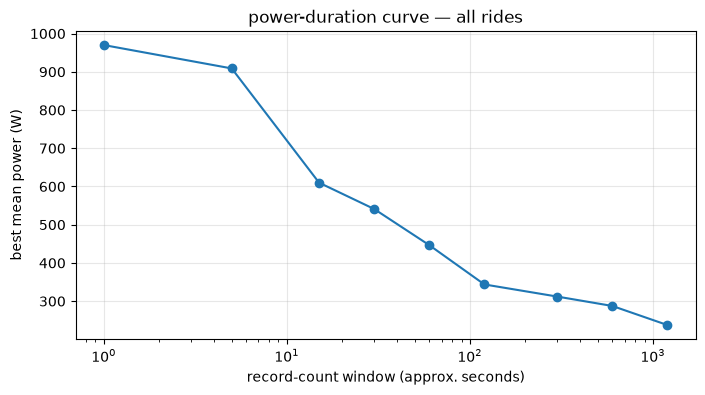

In [3]:
windows = [1, 5, 15, 30, 60, 120, 300, 600, 1200]
best = {}
for w in windows:
    m = 0
    for r in recs.values():
        p = r['power'].dropna()
        if len(p) >= w:
            m = max(m, p.rolling(w).mean().max())
    best[w] = m
curve = pd.Series(best)
print(curve.round(0).astype(int).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(curve.index, curve.values, marker='o')
ax.set_xlabel('record-count window (approx. seconds)')
ax.set_ylabel('best mean power (W)')
ax.set_title('power-duration curve — all rides')
ax.grid(alpha=0.3)
plt.show()

In [4]:
ftp = 0.95 * best[1200]
print(f'best 20 min: {best[1200]:.0f} W')
print(f'FTP estimate (95% of 20 min): {ftp:.0f} W')

best 20 min: 238 W
FTP estimate (95% of 20 min): 226 W


## training load — CTL / ATL / TSB
per-ride TSS from normalized power (30 s rolling, 4th-power mean) against the FTP estimate; PMC over 42/7-day windows.

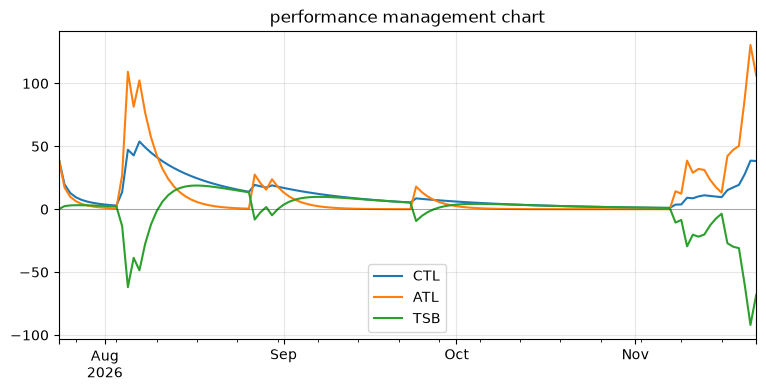

             CTL    ATL   TSB
2026-11-22  38.3  106.4 -68.1


In [5]:
def normalized_power(p):
    p = p.dropna()
    if len(p) < 30:
        return None
    roll = p.rolling(30).mean().dropna()
    return float((roll ** 4).mean() ** 0.25)

rows = []
for a in act.itertuples():
    if pd.isna(a.start_time) or not a.moving_s:
        continue
    p = recs[a.id]['power']
    np_ = normalized_power(p) or a.avg_power or 0
    tss = a.moving_s * np_ ** 2 / (ftp ** 2 * 3600) * 100
    rows.append({'date': a.start_time.normalize(), 'tss': tss})

daily = pd.DataFrame(rows).groupby('date').sum()
idx = pd.date_range(daily.index.min(), daily.index.max())
daily = daily.reindex(idx, fill_value=0)
daily['CTL'] = daily['tss'].ewm(span=42, min_periods=1).mean()
daily['ATL'] = daily['tss'].ewm(span=7, min_periods=1).mean()
daily['TSB'] = daily['CTL'] - daily['ATL']

fig, ax = plt.subplots(figsize=(9, 4))
daily[['CTL', 'ATL', 'TSB']].plot(ax=ax)
ax.axhline(0, color='k', lw=0.5, alpha=0.4)
ax.set_title('performance management chart')
ax.grid(alpha=0.3)
plt.show()
print(daily[['CTL', 'ATL', 'TSB']].tail(1).round(1).to_string())

## weekly distance + damped-trend forecast
Holt linear trend with damping — a naive flat-line forecast overfits the ramp; damping keeps long-horizon mileage sane.

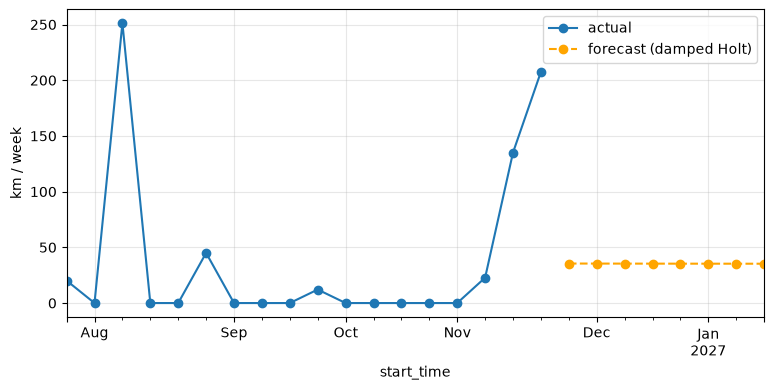

2026-11-29    35.5
2026-12-06    35.4
2026-12-13    35.4
2026-12-20    35.4
2026-12-27    35.3
2027-01-03    35.3
2027-01-10    35.3
2027-01-17    35.3
Freq: W-SUN


In [6]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

weekly = (act.dropna(subset=['start_time'])
            .set_index('start_time')['distance_m']
            .resample('W').sum() / 1000)
weekly = weekly[weekly.index >= weekly[weekly > 0].index.min()]

fit = ExponentialSmoothing(
    weekly, trend='add', damped_trend=True,
    initialization_method='estimated').fit()
fc = fit.forecast(8)

fig, ax = plt.subplots(figsize=(9, 4))
weekly.plot(ax=ax, marker='o', label='actual')
fc.plot(ax=ax, marker='o', ls='--', color='orange',
        label='forecast (damped Holt)')
ax.set_ylabel('km / week')
ax.legend()
ax.grid(alpha=0.3)
plt.show()
print(fc.round(1).to_string())

In [7]:
print('=== summary ===')
print(f"logical sessions: {len(act)}")
print(f"distance:         {act['distance_m'].sum()/1000:,.0f} km")
print(f"sessionized elapsed: {act['moving_s'].sum()/3600:.1f} h")
print(f"best 5 s power:   {best[5]:.0f} W")
print(f"best 20 min:      {best[1200]:.0f} W")
print(f"FTP estimate:     {ftp:.0f} W")
print(f"current form:     CTL {daily['CTL'].iloc[-1]:.0f} / "
      f"TSB {daily['TSB'].iloc[-1]:.0f}")

=== summary ===
logical sessions: 31
distance:         694 km
sessionized elapsed: 50.4 h
best 5 s power:   909 W
best 20 min:      238 W
FTP estimate:     226 W
current form:     CTL 38 / TSB -68
